# 🛡️ Project 1: SMS Spam Mail Detector
**QSkill AI/ML Internship**

This notebook walks through the end-to-end development of an SMS spam detection pipeline:
1. **Exploratory Data Analysis (EDA):** Class distribution and message length statistics.
2. **Text Preprocessing:** Tokenization, normalization, and stopword removal with NLTK.
3. **Feature Engineering & Model Benchmark:** Comparing Bag of Words (BoW) vs. TF-IDF across Naive Bayes, Logistic Regression, and Linear SVM.
4. **Cross-Validation & Hyperparameter Tuning:** 5-Fold Stratified CV with `GridSearchCV`.
5. **Comprehensive Evaluation:** Accuracy, Precision, Recall, F1, Confusion Matrix, and PR-AUC.
6. **Model Interpretability & Error Analysis:** Feature importance and false negative inspection.
7. **Model Serialization:** Exporting the pipeline for inference.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# Scikit-Learn tools
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, precision_recall_curve,
    average_precision_score, roc_auc_score
)

# Add project root to path for local src modules
nb_dir = os.path.dirname(os.path.abspath('__file__'))
proj_root = os.path.dirname(nb_dir) if 'notebooks' in nb_dir else os.path.abspath('.')
if proj_root not in sys.path:
    sys.path.insert(0, proj_root)

from src.data_loader import load_spam_data
from src.preprocess import clean_text

# Visualization formatting
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 120

## 1. Load Dataset & Exploratory Data Analysis

In [2]:
df = load_spam_data()
print(f"Total dataset shape: {df.shape}")
df.head()

Total dataset shape: (5574, 2)


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [3]:
# Add message length and word count features
df['char_length'] = df['message'].astype(str).apply(len)
df['word_count'] = df['message'].astype(str).apply(lambda s: len(s.split()))
df.groupby('label')[['char_length', 'word_count']].describe()

char_length                                                           \
            count        mean        std   min    25%    50%    75%    max   
label                                                                        
ham        4827.0   71.471929  58.326643   2.0   33.0   52.0   93.0  910.0   
spam        747.0  138.676037  28.871250  13.0  133.0  149.0  157.0  223.0   

      word_count                                                      
           count       mean        std  min   25%   50%   75%    max  
label                                                                 
ham       4827.0  14.304123  11.501631  1.0   7.0  11.0  19.0  171.0  
spam       747.0  23.911647   5.780174  2.0  22.0  25.0  28.0   35.0

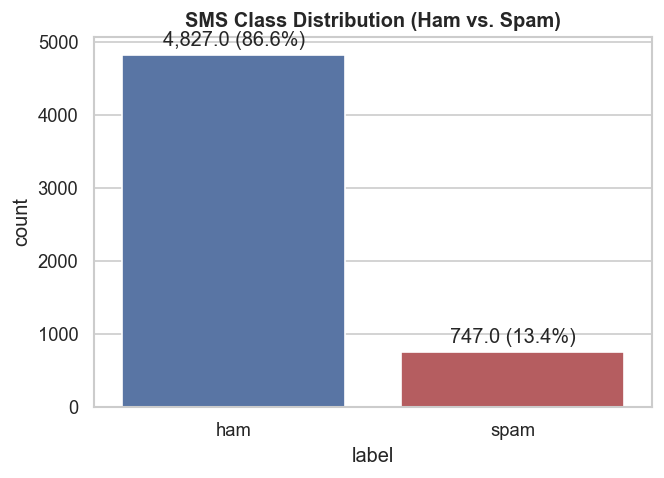

In [4]:
# Class Balance Visualization
plt.figure(figsize=(6, 4))
ax = sns.countplot(x='label', data=df, palette={'ham': '#4C72B0', 'spam': '#C44E52'}, hue='label', legend=False)
plt.title('SMS Class Distribution (Ham vs. Spam)', fontsize=12, weight='bold')
for p in ax.patches:
    h = p.get_height()
    ax.annotate(f'{h:,} ({h/len(df)*100:.1f}%)', (p.get_x() + p.get_width() / 2., h), ha='center', va='bottom', xytext=(0, 3), textcoords='offset points')
plt.show()

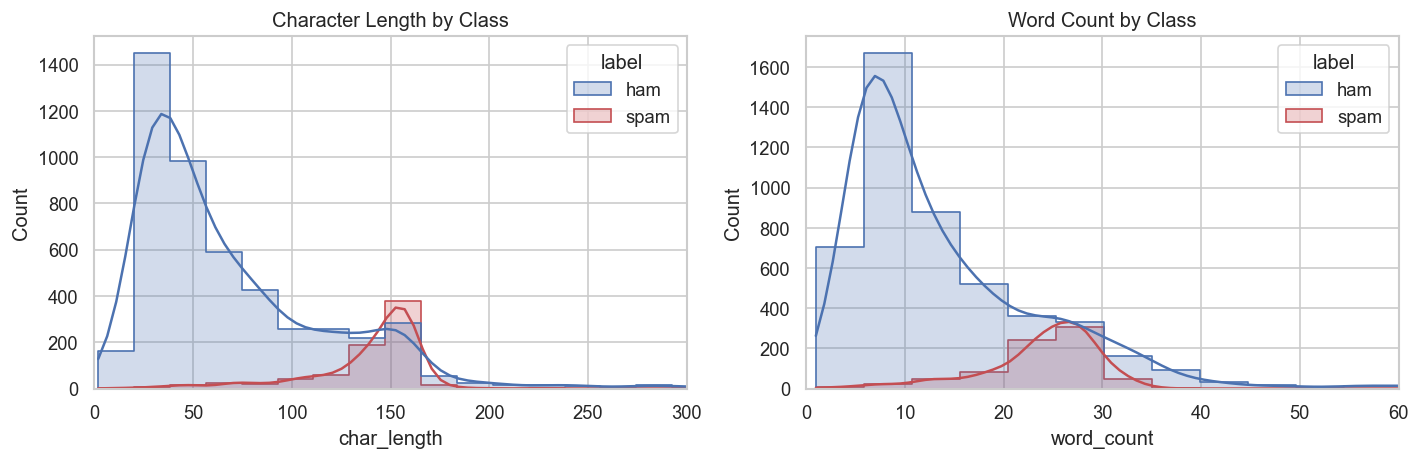

In [5]:
# Character & Word Length Distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=df, x='char_length', hue='label', bins=50, kde=True, palette={'ham': '#4C72B0', 'spam': '#C44E52'}, ax=axes[0], element='step', common_norm=False)
axes[0].set_title('Character Length by Class')
axes[0].set_xlim(0, 300)

sns.histplot(data=df, x='word_count', hue='label', bins=35, kde=True, palette={'ham': '#4C72B0', 'spam': '#C44E52'}, ax=axes[1], element='step', common_norm=False)
axes[1].set_title('Word Count by Class')
axes[1].set_xlim(0, 60)
plt.tight_layout()
plt.show()

## 2. Text Preprocessing

In [6]:
sample_msg = df[df['label'] == 'spam']['message'].iloc[0]
print('Original Spam Sample:\n', sample_msg)
print('\nCleaned & Normalized:\n', clean_text(sample_msg))

Original Spam Sample:
 Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's

Cleaned & Normalized:
 free entry wkly comp win fa cup final tkts st may text fa receive entry questionstd txt ratetcs apply


In [7]:
df['clean_message'] = df['message'].apply(clean_text)
df['target'] = (df['label'] == 'spam').astype(int)

# Stratified 80/20 train/test split
X_train, X_test, y_train, y_test, raw_train, raw_test = train_test_split(
    df['clean_message'], df['target'], df['message'],
    test_size=0.20, random_state=42, stratify=df['target']
)
print(f"Train size: {len(X_train)} | Test size: {len(X_test)}")

Train size: 4459 | Test size: 1115


## 3. Model Benchmark & 5-Fold Stratified Hyperparameter Tuning

In [8]:
feature_extractors = {
    'BoW': CountVectorizer(ngram_range=(1, 2)),
    'TF-IDF': TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)
}

classifiers = {
    'Multinomial Naive Bayes': (MultinomialNB(), {'clf__alpha': [0.01, 0.1, 0.5, 1.0, 2.0]}),
    'Logistic Regression': (LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced'), {'clf__C': [0.1, 1.0, 5.0, 10.0]}),
    'Linear SVM': (CalibratedClassifierCV(LinearSVC(random_state=42, max_iter=2000, dual='auto')), {'clf__estimator__C': [0.1, 1.0, 5.0, 10.0]})
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
benchmark_results = []
trained_models = {}

for vec_name, vectorizer in feature_extractors.items():
    for clf_name, (clf, param_grid) in classifiers.items():
        key = f"{clf_name} ({vec_name})"
        pipe = Pipeline([('vec', vectorizer), ('clf', clf)])
        grid = GridSearchCV(pipe, param_grid=param_grid, cv=cv, scoring='f1', n_jobs=-1)
        grid.fit(X_train, y_train)
        
        best_est = grid.best_estimator_
        preds = best_est.predict(X_test)
        probas = best_est.predict_proba(X_test)[:, 1]
        
        benchmark_results.append({
            'Model': clf_name,
            'Features': vec_name,
            'CV F1': grid.best_score_,
            'Test Accuracy': accuracy_score(y_test, preds),
            'Test Precision': precision_score(y_test, preds, zero_division=0),
            'Test Recall': recall_score(y_test, preds, zero_division=0),
            'Test F1': f1_score(y_test, preds, zero_division=0),
            'PR-AUC': average_precision_score(y_test, probas)
        })
        trained_models[key] = {'pipe': best_est, 'preds': preds, 'probas': probas}

results_df = pd.DataFrame(benchmark_results).sort_values('Test F1', ascending=False).reset_index(drop=True)
results_df

,Model,Features,CV F1,Test Accuracy,Test Precision,Test Recall,Test F1,PR-AUC
0,Logistic Regression,BoW,0.914383,0.986547,1.000000,0.899329,0.946996,0.971962
1,Linear SVM,BoW,0.924978,0.985650,0.992593,0.899329,0.943662,0.971277
2,Logistic Regression,TF-IDF,0.918768,0.982063,0.927152,0.939597,0.933333,0.972595
3,Multinomial Naive Bayes,TF-IDF,0.935116,0.982063,0.957447,0.906040,0.931034,0.970634
4,Linear SVM,TF-IDF,0.927590,0.980269,0.909677,0.946309,0.927632,0.973117
5,Multinomial Naive Bayes,BoW,0.937070,0.980269,0.937931,0.912752,0.925170,0.965397


## 4. Evaluation Visualizations & PR Curves

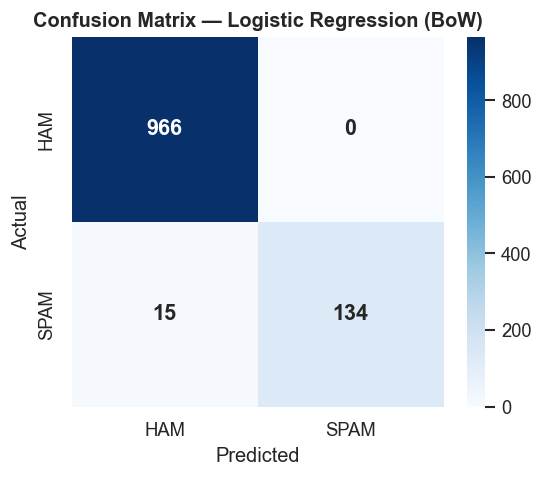

In [9]:
# Confusion matrix of top pipeline
best_name = results_df.iloc[0]['Model'] + f" ({results_df.iloc[0]['Features']})"
best_entry = trained_models[best_name]

cm = confusion_matrix(y_test, best_entry['preds'])
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['HAM', 'SPAM'], yticklabels=['HAM', 'SPAM'], annot_kws={'size': 13, 'weight': 'bold'})
plt.title(f'Confusion Matrix — {best_name}', fontsize=12, weight='bold')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

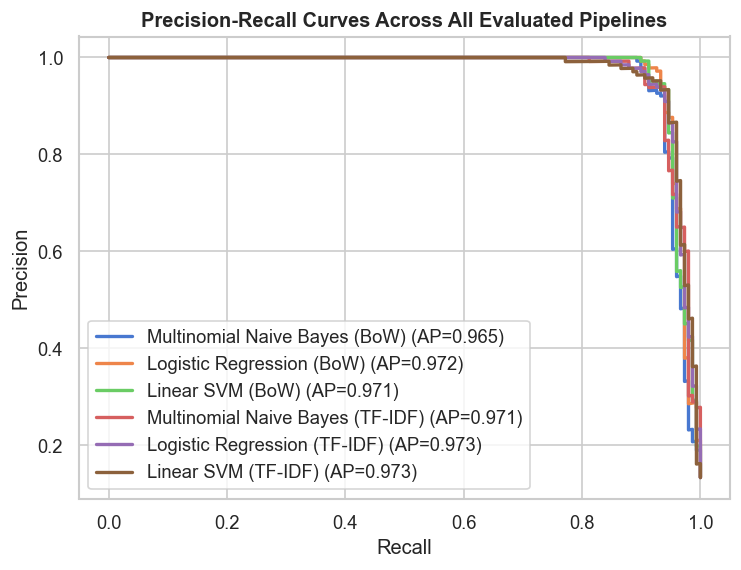

In [10]:
# Precision-Recall Curves
plt.figure(figsize=(7, 5))
for key, data in trained_models.items():
    p, r, _ = precision_recall_curve(y_test, data['probas'])
    ap = average_precision_score(y_test, data['probas'])
    plt.plot(r, p, lw=2, label=f"{key} (AP={ap:.3f})")

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curves Across All Evaluated Pipelines', weight='bold')
plt.legend(loc='lower left')
plt.show()

## 5. Feature Importance & Top Spam Indicators

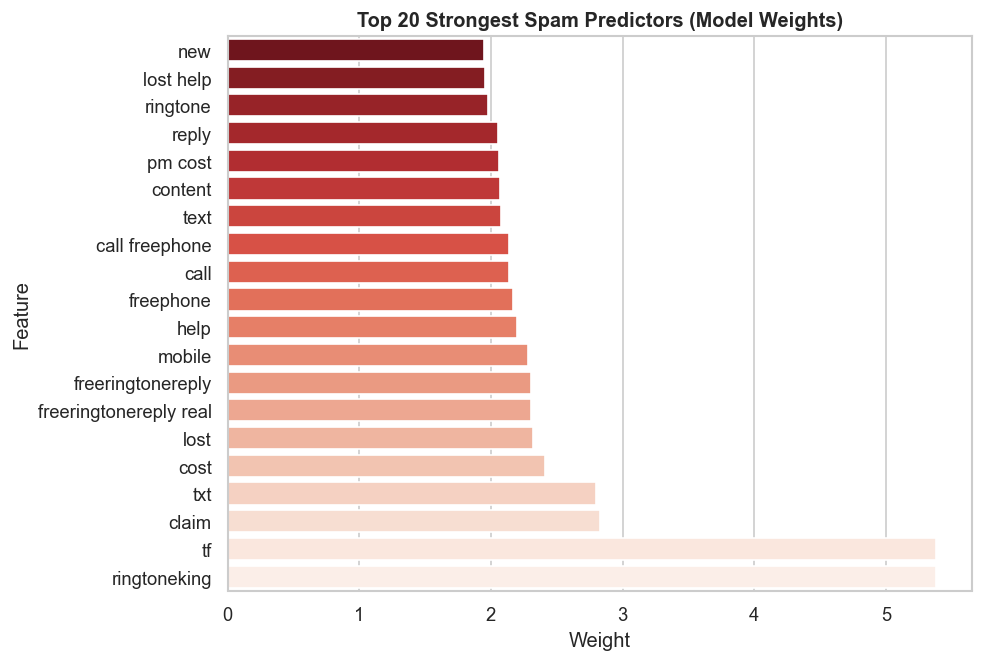

In [11]:
best_pipe = best_entry['pipe']
feature_names = np.array(best_pipe.named_steps['vec'].get_feature_names_out())
clf = best_pipe.named_steps['clf']

if hasattr(clf, 'coef_'):
    weights = clf.coef_[0]
else:
    weights = np.zeros(len(feature_names))

top20_idx = np.argsort(weights)[-20:]
top_words = pd.DataFrame({'Feature': feature_names[top20_idx], 'Weight': weights[top20_idx]}).sort_values('Weight', ascending=True)

plt.figure(figsize=(8, 6))
sns.barplot(x='Weight', y='Feature', data=top_words, palette='Reds_r', hue='Feature', legend=False)
plt.title('Top 20 Strongest Spam Predictors (Model Weights)', weight='bold')
plt.show()

## 6. Error Analysis

In [12]:
analysis_df = pd.DataFrame({
    'Original': raw_test.values,
    'Cleaned': X_test.values,
    'Actual': ['SPAM' if y == 1 else 'HAM' for y in y_test.values],
    'Predicted': ['SPAM' if y == 1 else 'HAM' for y in best_entry['preds']],
    'Spam_Prob': best_entry['probas']
})

errors = analysis_df[analysis_df['Actual'] != analysis_df['Predicted']]
print(f"Total Errors: {len(errors)} / {len(y_test)} ({len(errors)/len(y_test)*100:.2f}%)")
errors.head(10)

Total Errors: 15 / 1115 (1.35%)


,Original,Cleaned,Actual,Predicted,Spam_Prob
159,Hi ya babe x u 4goten bout me?' scammers getti...,hi ya babe goten bout scammers getting smartth...,SPAM,HAM,0.006691
203,Bought one ringtone and now getting texts cost...,bought one ringtone getting texts costing poun...,SPAM,HAM,0.262155
256,ROMCAPspam Everyone around should be respondin...,romcapspam everyone around responding well pre...,SPAM,HAM,0.035007
532,Sorry I missed your call let's talk when you h...,sorry missed call lets talk time im,SPAM,HAM,0.003854
602,More people are dogging in your area now. Call...,people dogging area call join like minded guys...,SPAM,HAM,0.112617
675,1000's of girls many local 2 u who r virgins 2...,girls many local virgins ready fil ur every se...,SPAM,HAM,0.205035
769,"Do you realize that in about 40 years, we'll h...",realize years well thousands old ladies runnin...,SPAM,HAM,0.006692
803,"""For the most sparkling shopping breaks from 4...",sparkling shopping breaks per person call visit,SPAM,HAM,0.173616
820,FreeMsg>FAV XMAS TONES!Reply REAL,freemsgfav xmas tonesreply real,SPAM,HAM,0.091263
826,Download as many ringtones as u like no restri...,download many ringtones like restrictions choo...,SPAM,HAM,0.276035


## 7. Model Serialization & Verification

In [13]:
out_model_path = os.path.join(proj_root, 'outputs', 'best_spam_pipeline.joblib')
joblib.dump(best_pipe, out_model_path)
print(f"Saved best pipeline to: {out_model_path}")

# Test loading and predicting on new sample
loaded_model = joblib.load(out_model_path)
test_message = "URGENT: Claim your $500 Amazon gift voucher today. Reply YES to confirm."
cleaned_test = clean_text(test_message)
pred = loaded_model.predict([cleaned_test])[0]
proba = loaded_model.predict_proba([cleaned_test])[0]
print(f"Test Message: '{test_message}'")
print(f"Verdict: {'SPAM' if pred == 1 else 'HAM'} (P(Spam) = {proba[1]*100:.2f}%)")

Saved best pipeline to: F:\Projects\Qskill\qskill-ml-internship\spam-detector\outputs\best_spam_pipeline.joblib
Test Message: 'URGENT: Claim your $500 Amazon gift voucher today. Reply YES to confirm.'
Verdict: SPAM (P(Spam) = 96.01%)
